# Step 3: 2D Poisson equation with a PINN

**Problem** on the unit square $\Omega = (0,1)^2$:

$$-\Delta u = f, \qquad u = 0 \text{ on } \partial\Omega, \qquad \Delta = u_{xx} + u_{yy}$$

$$f(x,y) = 2\pi^2 \sin(\pi x)\sin(\pi y), \qquad u(x,y) = \sin(\pi x)\sin(\pi y).$$

Natural 2D extension of `02_poisson_1d_pinn.ipynb`.

| Item | 1D | 2D |
|------|----|----|
| Input | $x$ | $(x,y)$ |
| Residual | $-u_{xx}-f$ | $-u_{xx}-u_{yy}-f$ |
| Boundary | 2 points | 4 edges |
| Classical | tridiagonal FD | 5-point stencil + Jacobi |

Run all cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

PI = np.pi
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)

set_seed(42)


device: cpu


## Reference solution, source, and 5-point finite differences

In [2]:
def exact_u(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    return np.sin(PI * x) * np.sin(PI * y)


def source_xy(x, y):
    if isinstance(x, torch.Tensor):
        return (2.0 * PI**2) * torch.sin(PI * x) * torch.sin(PI * y)
    return (2.0 * PI**2) * np.sin(PI * x) * np.sin(PI * y)


def finite_difference_poisson_2d(n=51, n_iter=8000):
    x = np.linspace(0.0, 1.0, n)
    y = np.linspace(0.0, 1.0, n)
    h = x[1] - x[0]
    X, Y = np.meshgrid(x, y, indexing="ij")
    f = source_xy(X, Y)
    u = np.zeros((n, n))
    for _ in range(n_iter):
        u_old = u.copy()
        u[1:-1, 1:-1] = (
            u_old[2:, 1:-1]
            + u_old[:-2, 1:-1]
            + u_old[1:-1, 2:]
            + u_old[1:-1, :-2]
            + h**2 * f[1:-1, 1:-1]
        ) / 4.0
    return x, y, u

x_fd, y_fd, u_fd = finite_difference_poisson_2d(51)
Xf, Yf = np.meshgrid(x_fd, y_fd, indexing="ij")
err_fd = np.linalg.norm(u_fd - exact_u(Xf, Yf)) / (np.linalg.norm(exact_u(Xf, Yf)) + 1e-12)
print("FD relative L2 error:", err_fd)


FD relative L2 error: 0.000328914509856916


## Network and collocation

- Interior points in $(0,1)^2$
- Boundary samples on four edges ($u \approx 0$)
- Residual: $\mathrm{res} = -u_{xx} - u_{yy} - f$

In [3]:
class MLP2d(nn.Module):
    def __init__(self, width=64, depth=5):
        super().__init__()
        layers = [nn.Linear(2, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), nn.Tanh()]
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x, y):
        return self.net(torch.stack([x, y], dim=-1)).squeeze(-1)


def grad(y, x):
    return torch.autograd.grad(
        y, x, grad_outputs=torch.ones_like(y), create_graph=True, retain_graph=True
    )[0]


def sample_interior(n, eps=1e-3):
    x = eps + (1.0 - 2 * eps) * torch.rand(n, device=device)
    y = eps + (1.0 - 2 * eps) * torch.rand(n, device=device)
    return x, y


def sample_boundary(n_edge, eps=1e-3):
    t = eps + (1.0 - 2 * eps) * torch.rand(n_edge, device=device)
    z = torch.zeros(n_edge, device=device)
    o = torch.ones(n_edge, device=device)
    x = torch.cat([t, t, z, o])
    y = torch.cat([z, o, t, t])
    return x, y


## Training

In [4]:
N_INT = 2048
N_EDGE = 128
EPOCHS = 10000
LR = 1e-3
W_BC = 100.0

model = MLP2d(width=64, depth=5).to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
history = []

for epoch in range(EPOCHS):
    opt.zero_grad()
    xi, yi = sample_interior(N_INT)
    xi = xi.clone().requires_grad_(True)
    yi = yi.clone().requires_grad_(True)
    ui = model(xi, yi)
    res = -grad(grad(ui, xi), xi) - grad(grad(ui, yi), yi) - source_xy(xi, yi)
    loss_pde = torch.mean(res**2)

    xb, yb = sample_boundary(N_EDGE)
    loss_bc = torch.mean(model(xb, yb) ** 2)

    loss = loss_pde + W_BC * loss_bc
    loss.backward()
    opt.step()
    history.append(loss.item())

    if (epoch + 1) % 2000 == 0:
        print(f"epoch {epoch+1:5d}  loss={loss.item():.3e}  pde={loss_pde.item():.3e}  bc={loss_bc.item():.3e}")


epoch  2000  loss=8.294e-03  pde=6.572e-03  bc=1.722e-05
epoch  4000  loss=1.468e-02  pde=3.280e-03  bc=1.140e-04
epoch  6000  loss=2.719e-03  pde=1.305e-03  bc=1.415e-05
epoch  8000  loss=2.403e-03  pde=8.302e-04  bc=1.572e-05
epoch 10000  loss=1.261e-02  pde=1.667e-03  bc=1.094e-04


## Visualization

relative L2 error  PINN: 2.3568e-02
relative L2 error  FD:   3.2891e-04


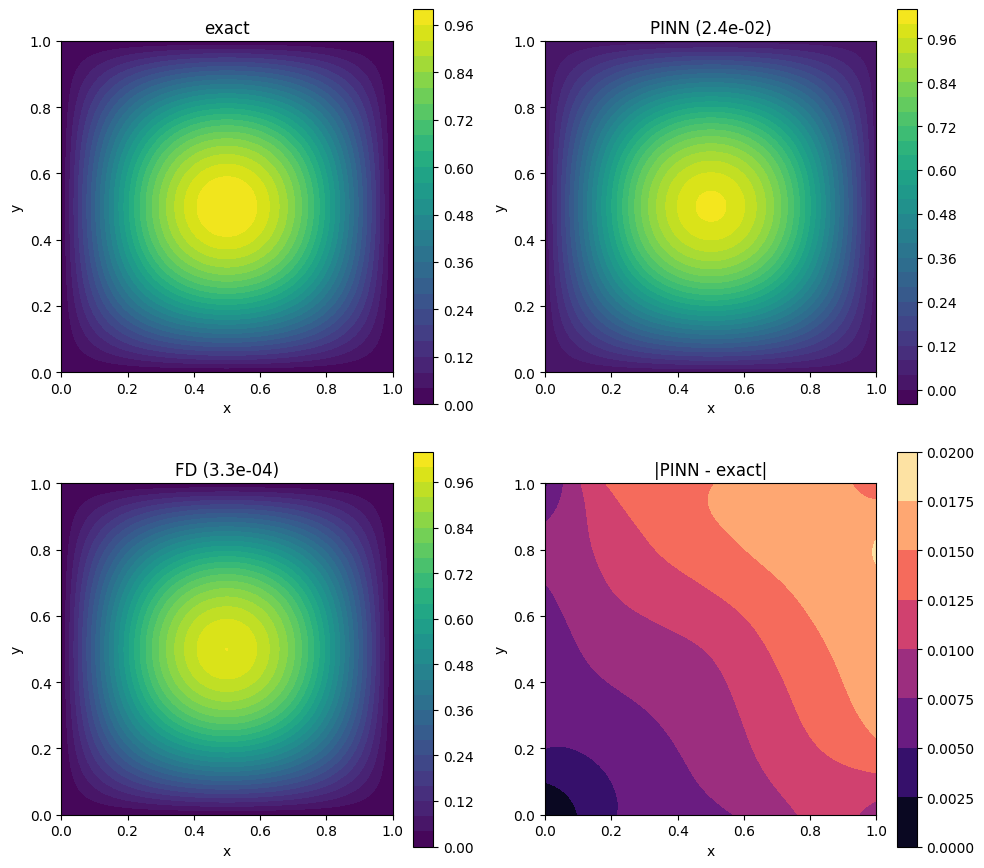

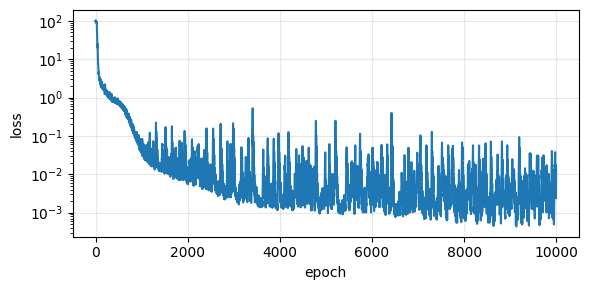

In [6]:
n_plot = 80
xp = np.linspace(0, 1, n_plot)
yp = np.linspace(0, 1, n_plot)
Xg, Yg = np.meshgrid(xp, yp, indexing="ij")
U_exact = exact_u(Xg, Yg)

xt = torch.tensor(Xg.ravel(), dtype=torch.float32, device=device)
yt = torch.tensor(Yg.ravel(), dtype=torch.float32, device=device)
with torch.no_grad():
    U_pinn = model(xt, yt).cpu().numpy().reshape(Xg.shape)

Xf, Yf = np.meshgrid(x_fd, y_fd, indexing="ij")
rel_pinn = np.linalg.norm(U_pinn - U_exact) / (np.linalg.norm(U_exact) + 1e-12)
rel_fd = np.linalg.norm(u_fd - exact_u(Xf, Yf)) / (np.linalg.norm(exact_u(Xf, Yf)) + 1e-12)
print(f"relative L2 error  PINN: {rel_pinn:.4e}")
print(f"relative L2 error  FD:   {rel_fd:.4e}")

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
kw = dict(levels=30, cmap="viridis")
axes[0, 0].contourf(Xg, Yg, U_exact, **kw); axes[0, 0].set_title("exact")
axes[0, 1].contourf(Xg, Yg, U_pinn, **kw); axes[0, 1].set_title(f"PINN ({rel_pinn:.1e})")
axes[1, 0].contourf(Xf, Yf, u_fd, **kw); axes[1, 0].set_title(f"FD ({rel_fd:.1e})")
axes[1, 1].contourf(Xg, Yg, np.abs(U_pinn - U_exact), cmap="magma"); axes[1, 1].set_title("|PINN - exact|")
# contourfで返されたQuadContourSetオブジェクトを保持し，colorbarを追加します．
cs0 = axes[0, 0].contourf(Xg, Yg, U_exact, **kw)
axes[0, 0].set_title("exact")
fig.colorbar(cs0, ax=axes[0, 0])

cs1 = axes[0, 1].contourf(Xg, Yg, U_pinn, **kw)
axes[0, 1].set_title(f"PINN ({rel_pinn:.1e})")
fig.colorbar(cs1, ax=axes[0, 1])

cs2 = axes[1, 0].contourf(Xf, Yf, u_fd, **kw)
axes[1, 0].set_title(f"FD ({rel_fd:.1e})")
fig.colorbar(cs2, ax=axes[1, 0])

cs3 = axes[1, 1].contourf(Xg, Yg, np.abs(U_pinn - U_exact), cmap="magma")
axes[1, 1].set_title("|PINN - exact|")
fig.colorbar(cs3, ax=axes[1, 1])


for ax in axes.ravel():
    ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3))
plt.semilogy(history); plt.xlabel("epoch"); plt.ylabel("loss"); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## Summary

| Method | Role |
|--------|------|
| Exact | Gold standard |
| 5-point FD + Jacobi | Grid reference |
| PINN | $-\Delta u = f$ + Dirichlet penalty |

**Exercises:** vary `W_BC`; try `SiLU`; next step: unit disk or a domain from conformal mapping.

For serious 2D elliptic problems, prefer sparse direct solvers; Jacobi is for teaching only.